## **LangGraph**

- LangChain constitut la briques de base avec abstractions haut niveau
- LangChain est très bien pour :
  - Prototyper vite, Chaîner prompts, outils et retrievers
  - Construire des cas simples à moyens
- LangChain montre ses limites quand on veut :
  - Des agents complexes, avec état persistant
  - Boucles, branches, retries
  - Human-in-the-loop
- Robustesse production

- LangGraph est un Framework destiné à créer et à gérer des agents d’IA ainsi que des flux de travail d’agents (Agents Work Flow) avec un état centralisé
- LangGraph Framework d’orchestration d’agents complexes sous forme de graphe / abstraction de bas niveau
- LangGraph modélise le système comme un graphe d’états et de transitions avec des possibilités d’utiliser :
   - Des boucles, des branches conditionnelles, des retours en arrière
   - Des workflows multi-étapes non linéaires
   - Une gestion d’état centralisée et structurée.
- LangGraph a été pensé pour des exécutions durables et reprenables  :
   - Sauvegarder l’état exact,  Reprendre après crash, 
   - Insérer un humain dans la boucle,
   - Faire du checkpointing
- LangGraph est aussi préférable pour des systèmes où la prévisibilité est importante (Workflow déterministes)
- Débogage avec LangSmith et LangGraph Studio
- Déploiement prêt pour la production

# **Concepts clés de LangGraph**
LangGraph modélise les flux de travail d’agents sous forme de graphes, avec trois composants fondamentaux qui assurent son fonctionnement : **l’état (State)**, **les nœuds (Nodes)** et **les arêtes (Edges)**.

Ces éléments fonctionnent ensemble pour créer des flux de travail flexibles, dynamiques et dotés d’un état.


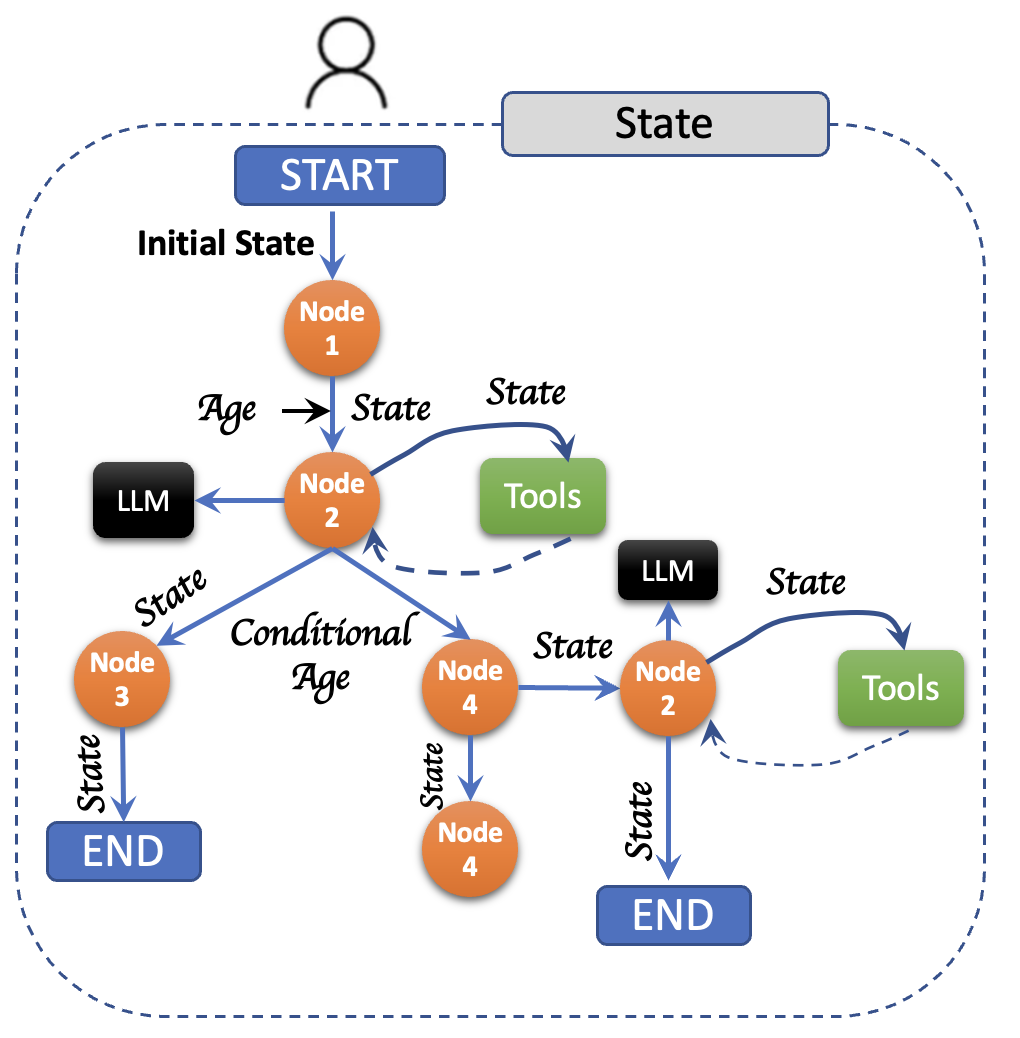

## 1. État (State)
- **Définition** : une structure de données partagée qui capture l’instantané actuel de l’application, généralement définie à l’aide d’un schéma comme un dictionnaire ou un modèle.
- **Rôle** : sert de point central pour tous les nœuds et toutes les arêtes, en stockant et en mettant à jour les données de l’application au fur et à mesure de leur traitement par les nœuds.
- **Schémas** : comprend un schéma principal pour l’état global, ainsi que des schémas facultatifs d’entrée/sortie ou privés pour la communication spécifique entre nœuds.
- **Reducers** : fonctions qui contrôlent la manière dont les mises à jour de l’état sont appliquées. Par défaut, les mises à jour remplacent les valeurs existantes, mais des reducers personnalisés peuvent ajouter ou modifier les données de manière spécifique pour agréger les données du state

## 2. Nœuds

- **Définition** : fonctions qui encapsulent la logique des agents, en prenant l’état actuel comme entrée, en exécutant des actions, puis en renvoyant un état mis à jour.
- **Exécution** : les nœuds fonctionnent en parallèle au sein d’une même itération (appelée *super-step*) ou de manière séquentielle entre plusieurs *super-steps*, en utilisant un système de passage de messages inspiré du modèle Pregel de Google.
- **Comportement** : les nœuds s’activent lorsqu’ils reçoivent des mises à jour de l’état et deviennent inactifs lorsqu’aucun message n’est reçu, ce qui conduit finalement à l’arrêt du graphe lorsque tous les nœuds sont inactifs.

## 3. Arêtes (Edges)
- **Définition** : fonctions qui déterminent le ou les prochains nœuds à exécuter en fonction de l’état actuel, soit par des transitions fixes, soit par une logique conditionnelle.
- **Types** :
  - **Arêtes normales** : transitions directes d’un nœud à un autre.
  - **Arêtes conditionnelles** : utilisent une logique pour décider dynamiquement du ou des prochains nœuds.
  - **Points d’entrée/sortie** : des nœuds spéciaux comme START et END définissent le début et la fin du graphe.
- **Exécution parallèle** : plusieurs arêtes sortantes depuis un nœud déclenchent l’exécution parallèle des nœuds de destination lors du *super-step* suivant.

# **Pourquoi c’est important**
L’approche de LangGraph fondée sur les graphes, avec une gestion robuste de l’état, des nœuds modulaires et des arêtes flexibles, permet de créer des flux de travail complexes et itératifs. Son système de passage de messages et son exécution par *super-steps* offrent un cadre puissant pour développer des applications dynamiques et dotées d’un état, telles que des systèmes multi-agents ou des IA conversationnelles, avec un contrôle précis des mises à jour d’état et du flux d’exécution.



**1- Définir l’état du graphe**
---
Dans LangGraph, l’**état** peut être un `TypedDict`, un modèle `Pydantic` ou une `dataclass`. Nous utiliserons `TypedDict` pour cet exemple. Par défaut, le schéma d’entrée et de sortie du graphe correspond à l’état.

- **TypedDict** – Utilisé pour définir la structure exacte d’un dictionnaire, en précisant les clés attendues et les types de leurs valeurs afin de rendre l’accès plus sûr à l’exécution.
  ```python
  from typing import TypedDict

  class State(TypedDict):
      messages: list[str]
      counter: int
  ```
- **Pydantic** – Une classe de validation de données qui impose les types et fournit une analyse automatique ainsi qu’une gestion des erreurs basée sur les annotations de types Python.
- **BaseModel** – `BaseModel` dans Pydantic est la classe de base permettant de créer des modèles de données qui valident et analysent les données à l’aide des annotations de types Python.  
  Elle impose automatiquement les types, convertit les données compatibles et fournit une sérialisation/désérialisation simple.
  ```python
  from pydantic import BaseModel

  class State(BaseModel):
      messages: list[str]
      counter: int
  ```
- **dataclass** – Une manière légère de créer des classes qui génèrent automatiquement des méthodes courantes (`__init__`, `__repr__`, etc.) pour contenir des données structurées.
  ```python
  from dataclasses import dataclass

  @dataclass
  class State:
      messages: list[str]
      counter: int
  ```

Voici un exemple simple : nous suivons une liste de messages ainsi qu’un champ entier supplémentaire en utilisant `TypedDict` :

In [9]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict,Literal, Sequence, List, Annotated
from langchain.messages import AnyMessage, HumanMessage, AIMessage, SystemMessage

In [10]:
class SimpleGraphState(TypedDict):
    messages : Sequence[AnyMessage]
    counter : int

**2-  Définir un nœud pour notre BasicGraph**

Cette fonction de nœud prend l’état actuel, ajoute un nouvel `AIMessage` à la liste des messages et met à jour un champ supplémentaire. Elle montre comment lire et modifier l’état dans un nœud LangGraph.

In [11]:
def graph_node(state: SimpleGraphState)->SimpleGraphState:
    """Reverse the String input"""
    query = state['messages'][-1].content
    reponse = AIMessage(content=f"Agent Response to query : [{query}], Output : {query.upper()[::-1]}")
    return {'messages':state['messages']+[reponse], "counter":10}

**3- Compiler notre BasicGraph à partir des composants `State` et `Node`**

Définissons maintenant un graphe simple contenant ce nœud. Nous utilisons `StateGraph` pour définir un graphe qui fonctionne sur cet état. Nous utilisons ensuite `add_node` pour ajouter ce nœud à notre graphe.

In [12]:
workflow = StateGraph(SimpleGraphState)
workflow.add_node("node",graph_node)
workflow.add_edge(START,"node")
workflow.add_edge("node", END)
graph = workflow.compile()

**4-  Visualisons à quoi ressemble notre graphe**

Nous utilisons `display` et `Image` d’IPython pour afficher le graphe LangGraph sous forme d’image PNG. La méthode `draw_mermaid_png()` génère une représentation visuelle du graphe, que nous pouvons afficher directement dans un notebook Jupyter.

In [13]:
from IPython.display import Image

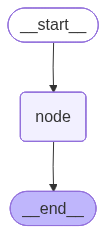

In [14]:
display(Image(graph.get_graph().draw_mermaid_png()))

**5- Invoquer le graph**

Le déroulement de cette invocation représente une simple mise à jour de l’état dans le graphe :

1. Le nœud reçoit l’état actuel, qui contient une liste de messages ainsi qu’un champ supplémentaire.  
2. Le nœud lit les messages, qui incluent déjà un `HumanMessage("My Name is Mohamed")`.  
3. Il ajoute un nouvel `Agent Response to query : [{query}], Output : {query.upper()[::-1]}` à la liste des messages.  
4. Il met à jour le champ `counter` à 10.  
5. L’état résultant contient désormais les deux messages ainsi que le champ supplémentaire mis à jour, prêt pour un traitement ultérieur ou pour le nœud suivant.

In [18]:
resp = graph.invoke({"messages": [HumanMessage("My Name is Mohamed")]})

In [19]:
resp

{'messages': [HumanMessage(content='My Name is Mohamed', additional_kwargs={}, response_metadata={}),
  AIMessage(content='Agent Response to query : [My Name is Mohamed], Output : DEMAHOM SI EMAN YM', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])],
 'counter': 10}

In [20]:
for message in resp['messages']:
    message.pretty_print()

================================ Human Message =================================

My Name is Mohamed
================================== Ai Message ==================================

Agent Response to query : [My Name is Mohamed], Output : DEMAHOM SI EMAN YM


## Exemple de avec Condional age

In [21]:
# 1) Définition de l'état partagé dans le workflow
class EmployeeState(TypedDict):
    name : str
    age : int
    salary : float
    decision :Literal["standard_hr","forced_hr"]
    result :str

In [22]:
# 2) Noeud de de vérification
def analyze_employee(state : EmployeeState)->EmployeeState:
    age = state['age']
    salary = state['salary']
    if(age<=30 and salary<=40000):
        state['decision'] = "standard_hr"
    else:
        state['decision']= "forced_hr"   
    return state       

In [23]:
# 3) Chemin 1
def standard_hr_process(state:EmployeeState)->EmployeeState:
    state['result'] = f"""Demande de {state['name']} 
    envoyée au traitement RH standard"""
    return state
    

In [24]:
# 4) Chemin 2
def forced_HR_validation(state:EmployeeState)->EmployeeState:
    state['result'] = f"""Demande de {state['name']} 
    envoyée à la validation RH forcée"""
    return state

In [25]:
# 5) Fonction de routage conditionnel
def router (state:EmployeeState):
    return state['decision']


In [26]:
wf = StateGraph(EmployeeState)
wf.add_node("analyze", analyze_employee)
wf.add_node("standard", standard_hr_process)
wf.add_node("forced", forced_HR_validation)
wf.add_edge(START, "analyze")
wf.add_conditional_edges(
    "analyze",
    router, {
        "standard_hr":"standard",
        "forced_hr":"forced"
    }
)
graph = wf.compile()

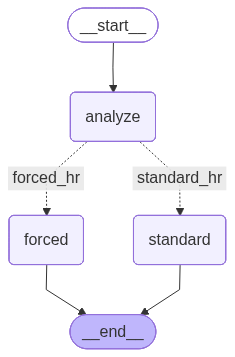

In [27]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [28]:
resp = graph.invoke({"name":"Mohamed","age":23, "salary":20000})

In [30]:
resp

{'name': 'Mohamed',
 'age': 23,
 'salary': 20000,
 'decision': 'standard_hr',
 'result': 'Demande de Mohamed \n    envoyée au traitement RH standard'}

In [31]:
resp = graph.invoke({"name":"Yassine","age":55, "salary":65000})
resp

{'name': 'Yassine',
 'age': 55,
 'salary': 65000,
 'decision': 'forced_hr',
 'result': 'Demande de Yassine \n    envoyée à la validation RH forcée'}

## Graph avec Loop

In [32]:
class AdministrativeFileState(TypedDict):
    name:str
    remaining_documents:int
    reminders:int
    status:Literal["incomplete","complete","validated"]

In [33]:
def verify_employee_file(state:AdministrativeFileState):
    if state['remaining_documents']>0:
        state['status']='incomplete'
    else:
        state['status']='complete'
    print("*"*50)
    print(f"Checking {state['name']}'s file, current status : {state['status']}")    
    return state    


In [34]:
def notify_employee(state : AdministrativeFileState):
    state['reminders']+=1
    if(state['remaining_documents'])>0:
        state['remaining_documents']-=1
    print("-"*50)
    print(f"Notification {state['reminders']} of employee {state['name']}")
    print(f"Remaining Documents : {state['remaining_documents']}")
    return state

In [35]:
def validate_file(state:AdministrativeFileState):
    state['status']="validated"
    print("="*40)
    print(f"Administrative File of {state['name']} succefully validated")
    return state
    

In [36]:
def router(state:AdministrativeFileState)->Literal['notify','validate']:
    if state['status']=='incomplete':
        return "notify"
    else:
        return "validate"

In [37]:
workflow = StateGraph(AdministrativeFileState)
workflow.add_node("file_verification",verify_employee_file)
workflow.add_node("employee_notification",notify_employee)
workflow.add_node("file_validation",validate_file)
workflow.set_entry_point("file_verification")
workflow.add_conditional_edges(
    "file_verification",
    router, {
        "notify":"employee_notification",
        "validate":"file_validation"
        }
)
workflow.add_edge("employee_notification","file_verification")

graph = workflow.compile()

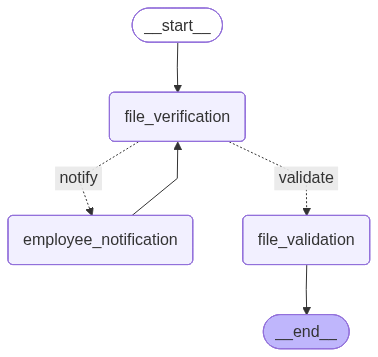

In [38]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [39]:
resp = graph.invoke(
    {"name":"Mohamed","remaining_documents":4, "reminders":0}
)

**************************************************
Checking Mohamed's file, current status : incomplete
--------------------------------------------------
Notification 1 of employee Mohamed
Remaining Documents : 3
**************************************************
Checking Mohamed's file, current status : incomplete
--------------------------------------------------
Notification 2 of employee Mohamed
Remaining Documents : 2
**************************************************
Checking Mohamed's file, current status : incomplete
--------------------------------------------------
Notification 3 of employee Mohamed
Remaining Documents : 1
**************************************************
Checking Mohamed's file, current status : incomplete
--------------------------------------------------
Notification 4 of employee Mohamed
Remaining Documents : 0
**************************************************
Checking Mohamed's file, current status : complete
Administrative File of Mohamed succefully 

In [43]:
print(resp)

{'name': 'Mohamed', 'remaining_documents': 0, 'reminders': 4, 'status': 'validated'}


## Example d'agent

In [49]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal, Sequence, Annotated
from langchain.messages import HumanMessage, SystemMessage, AnyMessage, ToolMessage
from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
from langchain.tools import tool
from langgraph.prebuilt import ToolNode
from dotenv.ipython import load_dotenv

In [50]:
load_dotenv(override=True)

True

In [51]:
# The Agent State
class SimpleAgentState(TypedDict):
    messages : Annotated[Sequence[BaseMessage], add_messages]

In [52]:
## LLM
llm = ChatOpenAI(model="gpt-4o", temperature=0)

In [53]:
# Agent Node
def agent_node(state : SimpleAgentState)->SimpleAgentState:
    response = llm.invoke(state['messages'])
    print("*"*50)
    print(f"The agent invoke LLM with {len(state['messages'])} messages")
    return {"messages":[response]}

In [55]:
# Tools
@tool
def add_tool(a:float, b:float)->float:
    """
    Add 2 numbers a and b
    """
    print(f"\nAdd Numbers Tool Invoked for inputs:  a = {a}, b={b}")
    return a+b

@tool
def multiply_tool(a:float, b:float)->float:
    """
    Multiply 2 numbers a and b
    """
    print(f"\nMultiply Numbers Tool Invoked for inputs:  a = {a}, b={b}")
    return a*b

@tool
def divide_tool(a:float, b:float)->float:
    """
    Divide 2 numbers a by b
    """
    print(f"\nDivide Numbers Tool Invoked for inputs:  a = {a}, b={b}")
    return a/b

tools = [add_tool, multiply_tool, divide_tool]
llm_with_tools = llm.bind_tools(tools)

In [56]:
def assistant(state : SimpleAgentState):
    resp = llm_with_tools.invoke(state['messages'])
    return {"messages":[resp]}

In [57]:
def should_continue(state:SimpleAgentState):
    if not state['messages'][-1].tool_calls:
        return "end"
    else:
        return "continue"

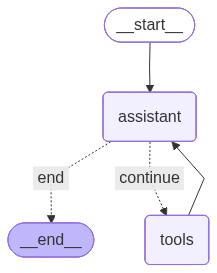

In [58]:
workflow = StateGraph(SimpleAgentState)
workflow.add_node("assistant", assistant)
workflow.add_node("tools", ToolNode(tools))
workflow.add_edge(START, "assistant")
workflow.add_conditional_edges(
    "assistant", should_continue, {
        "end" : END,
        "continue" : "tools"
    }
)
workflow.add_edge("tools","assistant")
graph =workflow.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [59]:
resp = graph.invoke(input={
    "messages":[
        HumanMessage("Add 5 to 80 then multiply by 23 et donne moi un proverbe en arabe")
        ]
        }
        )


Add Numbers Tool Invoked for inputs:  a = 5.0, b=80.0
Multiply Numbers Tool Invoked for inputs:  a = 85.0, b=23.0



In [60]:
print(resp['messages'][-1].content)

Le résultat de l'addition de 5 à 80 est 85, et le résultat de la multiplication par 23 est 1955.

Voici un proverbe en arabe : "الصبر مفتاح الفرج" qui signifie "La patience est la clé de la délivrance."


In [61]:
stream = graph.stream(input={
    "messages":[
        HumanMessage("Add 5 to 80 then multiply by 23 et donne moi un proverbe en arabe")
        ]
        }, stream_mode="values")

In [62]:
for item in stream:
    message = item['messages'][-1]
    if(isinstance(message, BaseMessage)):
       message.pretty_print()

================================ Human Message =================================

Add 5 to 80 then multiply by 23 et donne moi un proverbe en arabe
================================== Ai Message ==================================
Tool Calls:
  add_tool (call_JTNrEFW6kKnkLBKpRQjH0ljr)
 Call ID: call_JTNrEFW6kKnkLBKpRQjH0ljr
  Args:
    a: 5
    b: 80
  multiply_tool (call_BkT3lQ94wYXjFnYBORsrK3dW)
 Call ID: call_BkT3lQ94wYXjFnYBORsrK3dW
  Args:
    a: 85
    b: 23

Add Numbers Tool Invoked for inputs:  a = 5.0, b=80.0

Multiply Numbers Tool Invoked for inputs:  a = 85.0, b=23.0
================================= Tool Message =================================
Name: multiply_tool

1955.0
================================== Ai Message ==================================

Le résultat de l'addition de 5 à 80 est 85, et le résultat de la multiplication de 85 par 23 est 1955.

Voici un proverbe en arabe : "الصبر مفتاح الفرج" qui signifie "La patience est la clé de la délivrance."


### **Example 6 : Agent with Tools and Memory**

In [63]:
from langgraph.checkpoint.memory import InMemorySaver

In [64]:
memory = InMemorySaver()
graph_with_memory = workflow.compile(checkpointer=memory)

In [65]:
config = {"configurable":{"thread_id":"1"}}
result = graph_with_memory.invoke(
    {"messages": [HumanMessage(content="Mon nom est Mohamed")]},
    config=config
)
print(result['messages'][-1].content)

Bonjour Mohamed ! Comment puis-je vous aider aujourd'hui ?


In [66]:

result = graph_with_memory.invoke(
    {"messages": [HumanMessage(content="C'est quoi mon nom?")]},
    config=config
)
print(result['messages'][-1].content)

Votre nom est Mohamed.


In [67]:
current_state = graph_with_memory.get_state(config).values['messages']
current_state

[HumanMessage(content='Mon nom est Mohamed', additional_kwargs={}, response_metadata={}, id='824fa38e-1900-4578-9f9d-78591c304bff'),
 AIMessage(content="Bonjour Mohamed ! Comment puis-je vous aider aujourd'hui ?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 12, 'prompt_tokens': 105, 'total_tokens': 117, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_6dd86a7be3', 'id': 'chatcmpl-DX9CA2AQrjxbJ5Xb2NTgP9xfNldi9', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019db116-9b00-75f1-926a-15c921111db5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 105, 'output_tokens': 12, 'total_tokens': 117, 'input_token_details': {'audio': 0, 'cache_read':

## Agentic Rag

### Step 1: Import Additional Libraries for RAG

In [68]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_openai import OpenAIEmbeddings
from langchain_openai import ChatOpenAI
from IPython.display import Markdown
import os

### Step 2: Load AI Initiative Documents (PDFs)

In [96]:
# Path of all pdfs
pdf_paths = [f"./pdfs/{file}" for file in os.listdir("./pdfs")]
pdf_paths

['./pdfs/these_doctorat.pdf']

In [71]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
# Creating an PDF loader object
loader = PyPDFDirectoryLoader(path="./pdfs/")

### Step 3: Split Documents into Chunks

In [72]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=200
)
# Load and split documents
chunks = loader.load_and_split(text_splitter=text_splitter)

In [74]:
print(len(chunks))

237


### Step 4: Create Vector Store with Embeddings

In [75]:
### Step 4: Create Vector Store with Embeddings

from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import Chroma

# Initialize OpenAI embedding model (text-embedding-ada-002)
embedding_model = OpenAIEmbeddings(model="text-embedding-ada-002")
# Create vector store from documents
vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embedding_model,
    collection_name="these_doctorat"
)
# Create retriever for similarity search which fetches 10 relevant chunks
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10}
)

### Step 5: Test RAG Retrieval (Manual)

In [99]:
### Step 5: Test RAG Retrieval (Manual)
# Test query
test_query = "Sujet de thèse et Auteur de cette thèse de doctorat"

print(f"🔍 Test Query: {test_query}")
print("="*50)

# Retrieve relevant documents
relevant_docs = retriever.invoke(test_query)

print(f"\n Retrieved {len(relevant_docs)} relevant chunks:")

# Display top 3 results
for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"\n Result {i}:")
    print(f"\n - Source: {doc.metadata.get('source', 'Unknown')}")
    print(f"\n - Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"\n - Content: {doc.page_content[:100]}...")
    print("-"*50 + "\n")

🔍 Test Query: Sujet de thèse et Auteur de cette thèse de doctorat


08:40:38 [INFO] HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"



 Retrieved 10 relevant chunks:

 Result 1:

 - Source: pdfs/these_doctorat.pdf

 - Page: 3

 - Content: ACKNOWLEDGMENTS
In this month of October, as the days grow colder and winter draws near, I arrive at...
--------------------------------------------------


 Result 2:

 - Source: pdfs/these_doctorat.pdf

 - Page: 161

 - Content: Pasteur, SINERGIES laboratory. His research is
focused on artificial intelligence, particularly in
o...
--------------------------------------------------


 Result 3:

 - Source: pdfs/these_doctorat.pdf

 - Page: 39

 - Content: Publications
The research presented in this thesis has been the subject of the following publication...
--------------------------------------------------



### Step 6: Implement `retriever_tool`

In [ ]:
@tool
def retriever_tool(query: str) -> str:
    """ Permet de cherercher des informations sur une thèse de doctorat :
    - Titre de la thèses
    - Membres de jurys
    - Directeurs et co-directeurs de thèse
    - Chapitres
    - Résumé
Args:
    query: Question posée par l'utilisateur
Returns:
    str: Réponse détaillée
    """
    try:
        # Retrieve relevant document chunks
        relevant_document_chunks = retriever.invoke(query)
        context_list = [d.page_content for d in relevant_document_chunks]
        context_for_query = ". ".join(context_list)
        return context_for_query
    except Exception as e:
        return f"Error querying private database: {str(e)}"


In [80]:
model = ChatOpenAI(model="gpt-4o-mini", temperature=0)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

#### LangGraph Agentic RAG

In [81]:
import logging
from typing import Annotated, Sequence, Literal
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain.messages import SystemMessage, HumanMessage, AIMessage

In [82]:
# Configure logging to see agent's decision-making process
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    datefmt='%H:%M:%S'
)
logger = logging.getLogger(__name__)

In [83]:
class SimpleAgentState(TypedDict):
    messages: Annotated[Sequence, add_messages]

In [84]:
agentic_rag_system_message =""" 
Vous êtes un assistant spécialisé dans la recherche des informations concernant des thèses de doctorat.
Si la réponse ne peut pas être trouvée dans le contexte, répondez par : "Je ne sais pas - cette information n’est pas disponible dans nos rapports d’analystes."
"""

In [105]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node that calls the LLM with system prompt and current state."""
    logger.info("AGENT NODE: Processing request...")
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])
    logger.info("   Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)
    # Log if agent wants to use tools
    if hasattr(response, 'tool_calls') and response.tool_calls:
        logger.info(f"   ✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"      {i}. {tool_call['name']}")
            logger.info(f"      {i}. {tool_call['args']}")
    else:
        logger.info("   ✓ Agent generated final response (no tools needed)")
    return {"messages": [response]}

In [106]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:    
        """Determines whether to continue to tools or end."""
        last_message = state["messages"][-1]

        if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
            logger.info("🔀 ROUTING: Continuing to TOOLS node")
            return "tools"
        logger.info("ROUTING: Ending workflow (final response ready)")
        return "end"

In [107]:
# Create workflow

workflow = StateGraph(SimpleAgentState)
# Create tool node with logging
original_tool_node = ToolNode(tools)

def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info(f"Tools executed successfully")
    return result

# Add nodes to graph
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)

# Set entry point
workflow.set_entry_point("agent")

# Add conditional edge from agent
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)

# Add edge from tools back to agent
workflow.add_edge("tools", "agent")
graph = workflow.compile()
logger.info("✅ Enhanced agent created successfully\n")

09:00:37 [INFO] ✅ Enhanced agent created successfully



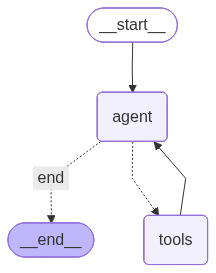

In [104]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [108]:
resp = graph.invoke({"messages":[
    HumanMessage(""" Sujet de la thèse, auteur, liste des membres de jury et directeurs de la thèse""")
    ]
    })

09:00:45 [INFO] AGENT NODE: Processing request...
09:00:45 [INFO]    Calling LLM with tools...
09:00:47 [INFO] HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
09:00:47 [INFO]    ✓ Agent decided to use 1 tool(s)
09:00:47 [INFO]       1. retriever_tool
09:00:47 [INFO]       1. {'query': 'Sujet de la thèse, auteur, liste des membres de jury et directeurs de la thèse'}
09:00:47 [INFO] 🔀 ROUTING: Continuing to TOOLS node
09:00:47 [INFO] TOOL NODE: Executing tools...
09:00:49 [INFO] HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"
09:00:49 [INFO] Tools executed successfully
09:00:49 [INFO] AGENT NODE: Processing request...
09:00:49 [INFO]    Calling LLM with tools...
09:00:54 [INFO] HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
09:00:54 [INFO]    ✓ Agent generated final response (no tools needed)
09:00:54 [INFO] ROUTING: Ending workflow (final response ready)


In [94]:
print(display(Markdown(resp['messages'][-1].content)))

Voici les informations concernant la thèse :

- **Sujet de la thèse** : Optimisation de la gestion des ressources préhospitalières et détection des émotions dans les appels d'urgence à l'aide de l'intelligence artificielle.
- **Auteur** : Omar Elfahim
- **Directeurs de thèse** : 
  - Pr. Mohamed Youssfi
  - Pr. Oussama Barakat
  - Pr. Mohamed Mestari (co-directeur)
- **Membres du jury** :
  - Professeur Abdelhakim Artiba
  - Professeur Mohamed Kissi
  - Professeur Elhabib Nfaoui (rapporteurs)
  - Professeur Omar Bouattane
  - Professeur Mohamed Embarki (examiners)

Si vous avez besoin d'autres informations, n'hésitez pas à demander !

None


## **Human In The Loop**

In [5]:
import os
from typing_extensions import TypedDict, Literal

from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from IPython.display import Markdown, Image

In [2]:
# =========================
# 1) Définition de l'état
# =========================
class EmailState(TypedDict, total=False):
    recipient: str
    subject: str
    intent: str
    draft: str
    approved: bool
    feedback: str


# =========================
# 2) LLM OpenAI
# =========================
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.4,
    api_key=os.environ["OPENAI_API_KEY"],
)


In [3]:
# =========================
# 3) Nœud: rédaction du brouillon
# =========================
def write_draft(state: EmailState):
    feedback = state.get("feedback", "")
    previous_draft = state.get("draft", "")

    prompt = f"""
Tu es un assistant qui rédige des emails professionnels en français.

Destinataire: {state["recipient"]}
Sujet: {state["subject"]}
Objectif: {state["intent"]}

Brouillon précédent:
{previous_draft if previous_draft else "(aucun)"}

Commentaire humain:
{feedback if feedback else "Aucun commentaire. Rédige un premier brouillon."}

Instructions:
- Rédige un email clair, poli et concis
- Si un commentaire humain est fourni, réécris le brouillon en en tenant compte
- Retourne uniquement le corps de l'email
"""

    response = llm.invoke(prompt)
    return {"draft": response.content}


# =========================
# 4) Nœud Human-in-the-loop
#    -> interrompt le graphe
# =========================
def human_review(state: EmailState):
    review = interrupt({
        "type": "human_review",
        "message": "Merci de valider ou rejeter le brouillon",
        "draft": state["draft"],
        "expected_response": {
            "approved": "bool",
            "feedback": "str (optionnel, utile si rejet)"
        }
    })

    return {
        "approved": review["approved"],
        "feedback": review.get("feedback", "")
    }


# =========================
# 5) Route après review
# =========================
def route_after_review(state: EmailState) -> Literal["send_email", "write_draft"]:
    if state["approved"]:
        return "send_email"
    return "write_draft"


# =========================
# 6) Nœud: envoi du mail
#    Ici on simule l'envoi
# =========================
def send_email(state: EmailState):
    print("\n=== EMAIL ENVOYÉ ===")
    print(f"À      : {state['recipient']}")
    print(f"Sujet  : {state['subject']}")
    print("Corps  :")
    print(state["draft"])
    print("====================\n")

    return {}

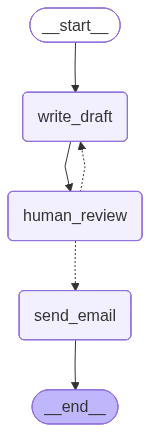

In [6]:
# =========================
# 7) Construction du graphe
# =========================
builder = StateGraph(EmailState)

builder.add_node("write_draft", write_draft)
builder.add_node("human_review", human_review)
builder.add_node("send_email", send_email)

builder.add_edge(START, "write_draft")
builder.add_edge("write_draft", "human_review")
builder.add_conditional_edges("human_review", route_after_review)
builder.add_edge("send_email", END)

graph = builder.compile(checkpointer=InMemorySaver())
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
# =========================
# 8) Exécution interactive CLI
# =========================
config = {"configurable": {"thread_id": "email-demo-1"}}

initial_input = {
        "recipient": "client@entreprise.com",
        "subject": "Proposition de rendez-vous",
        "intent": "Écrire un email au format markdown pour proposer un rendez-vous la semaine prochaine afin de présenter notre offre.",
}

result = graph.invoke(initial_input, config=config)

In [8]:
print(result)

{'recipient': 'client@entreprise.com', 'subject': 'Proposition de rendez-vous', 'intent': 'Écrire un email au format markdown pour proposer un rendez-vous la semaine prochaine afin de présenter notre offre.', 'draft': "Bonjour,\n\nJ'espère que vous allez bien.\n\nJe me permets de vous contacter pour vous proposer un rendez-vous la semaine prochaine afin de vous présenter notre offre. Nous serions ravis de discuter de vos besoins et de vous montrer comment nos solutions peuvent vous être bénéfiques.\n\nPourriez-vous me faire savoir vos disponibilités ? Je suis flexible et peux m'adapter à votre emploi du temps.\n\nDans l'attente de votre retour, je vous souhaite une excellente journée.\n\nCordialement,\n\n[Votre Nom]  \n[Votre Poste]  \n[Votre Entreprise]  \n[Votre Numéro de Téléphone]  \n[Votre Adresse Email]  ", '__interrupt__': [Interrupt(value={'type': 'human_review', 'message': 'Merci de valider ou rejeter le brouillon', 'draft': "Bonjour,\n\nJ'espère que vous allez bien.\n\nJe me 

In [9]:
# Tant qu'on a une interruption humaine, on demande l'avis de l'utilisateur
while "__interrupt__" in result:
        payload = result["__interrupt__"][0].value
        print("\n--- BROUILLON À VALIDER ---")
        print(display(Markdown(payload["draft"])))
        print("---------------------------")
        print("\n",payload['message'])
        answer = input("\nValider ce brouillon ? (o/n) : ").strip().lower()
        print("Réponse : ",answer)

        if answer == "o":
            result = graph.invoke(
                Command(resume={"approved": True, "feedback": ""}),
                config=config
            )
        else:
            comment = input("Commentaire de correction : ").strip()
            print("Commentaire : ",comment)
            result = graph.invoke(
                Command(resume={"approved": False, "feedback": comment}),
                config=config
            )

print("Workflow terminé.")


--- BROUILLON À VALIDER ---


Bonjour,

J'espère que vous allez bien.

Je me permets de vous contacter pour vous proposer un rendez-vous la semaine prochaine afin de vous présenter notre offre. Nous serions ravis de discuter de vos besoins et de vous montrer comment nos solutions peuvent vous être bénéfiques.

Pourriez-vous me faire savoir vos disponibilités ? Je suis flexible et peux m'adapter à votre emploi du temps.

Dans l'attente de votre retour, je vous souhaite une excellente journée.

Cordialement,

[Votre Nom]  
[Votre Poste]  
[Votre Entreprise]  
[Votre Numéro de Téléphone]  
[Votre Adresse Email]  

None
---------------------------

 Merci de valider ou rejeter le brouillon
Réponse :  n
Commentaire :  à la fin tu ajoute, Bien crodialement : M.Youssfi

--- BROUILLON À VALIDER ---


Bonjour,

J'espère que vous allez bien.

Je me permets de vous contacter pour vous proposer un rendez-vous la semaine prochaine afin de vous présenter notre offre. Nous serions ravis de discuter de vos besoins et de vous montrer comment nos solutions peuvent vous être bénéfiques.

Pourriez-vous me faire savoir vos disponibilités ? Je suis flexible et peux m'adapter à votre emploi du temps.

Dans l'attente de votre retour, je vous souhaite une excellente journée.

Bien cordialement,  
M. Youssfi  
[Votre Poste]  
[Votre Entreprise]  
[Votre Numéro de Téléphone]  
[Votre Adresse Email]  

None
---------------------------

 Merci de valider ou rejeter le brouillon
Réponse :  o

=== EMAIL ENVOYÉ ===
À      : client@entreprise.com
Sujet  : Proposition de rendez-vous
Corps  :
Bonjour,

J'espère que vous allez bien.

Je me permets de vous contacter pour vous proposer un rendez-vous la semaine prochaine afin de vous présenter notre offre. Nous serions ravis de discuter de vos besoins et de vous montrer comment nos solutions peuvent vous être bénéfiques.

Pourriez-vous me faire savoir vos disponibilités ? Je suis flexible et peux m'adapter à votre emploi du temps.

Dans l'attente de votre retour, je vous souhaite une excellente journée.

Bien cordialement,  
M. Youssfi  
[Votre Poste]  
[Votre Entreprise]  
[Votre Numéro de Téléphone]  
[Votre Adresse Email]  

Workflow terminé.


### Multi Agent System

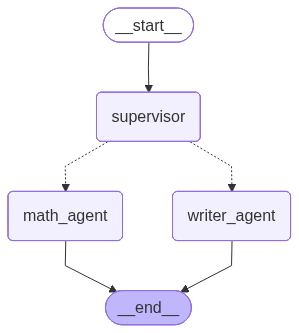

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict, Literal

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from IPython.display import Image


# Etat partagé
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    next: str



# Sortie attendue du supervisor
class Router(TypedDict):
    next: Literal["math_agent", "writer_agent"]


llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# LLM avec sortie structurée
router_llm = llm.with_structured_output(Router)


# Supervisor : utilise le LLM pour décider du prochain agent
def supervisor_node(state: AgentState):
    decision = router_llm.invoke([
        SystemMessage(content=(
            "Tu es un supervisor dans un système multi-agents.\n"
            "Choisis l'agent le plus adapté selon la demande utilisateur.\n"
            "- math_agent : pour calculs, équations, problèmes mathématiques\n"
            "- writer_agent : pour rédaction, reformulation, emails, textes\n"
            "Réponds uniquement avec le champ structuré attendu."
        )),
        *state["messages"]
    ])

    return {"next": decision["next"]}


# Sous-agent math
def math_agent_node(state: AgentState):
    response = llm.invoke([
        SystemMessage(content="Tu es un agent expert en mathématiques. Réponds clairement et correctement."),
        *state["messages"]
    ])
    return {
        "messages": [AIMessage(content=response.content, name="math_agent")]
    }


# Sous-agent rédaction
def writer_agent_node(state: AgentState):
    response = llm.invoke([
        SystemMessage(content="Tu es un agent expert en rédaction. Rédige de manière claire et professionnelle."),
        *state["messages"]
    ])
    return {
        "messages": [AIMessage(content=response.content, name="writer_agent")]
    }


# Fonction de routage
def route_after_supervisor(state: AgentState):
    return state["next"]


# Construction du graphe
builder = StateGraph(AgentState)

builder.add_node("supervisor", supervisor_node)
builder.add_node("math_agent", math_agent_node)
builder.add_node("writer_agent", writer_agent_node)

builder.add_edge(START, "supervisor")

builder.add_conditional_edges(
    "supervisor",
    route_after_supervisor,
    {
        "math_agent": "math_agent",
        "writer_agent": "writer_agent",
    }
)

builder.add_edge("math_agent", END)
builder.add_edge("writer_agent", END)

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
result = graph.invoke({
    "messages": [HumanMessage(content="Calcule 18 * 27")]
})

print(result["messages"][-1].content)

2026-04-23 08:27:05,237 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-04-23 08:27:06,140 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


18 * 27 = 486.


In [14]:
result = graph.invoke({
    "messages": [HumanMessage(content="Rédige un email pour demander un rendez-vous")]
})

print(result["messages"][-1].content)

2026-04-23 08:27:28,092 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-04-23 08:27:31,240 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


Objet : Demande de rendez-vous

Bonjour [Nom du destinataire],

J'espère que vous allez bien.

Je me permets de vous contacter afin de solliciter un rendez-vous pour discuter de [préciser l'objet de la rencontre, par exemple : "notre collaboration", "un projet en cours", "des opportunités d'affaires", etc.]. Je pense qu'un échange direct serait bénéfique pour [expliquer brièvement l'intérêt de la rencontre].

Je suis disponible aux dates suivantes : [proposer quelques créneaux horaires], mais je reste flexible et je m'adapterai à votre emploi du temps.

Je vous remercie par avance pour votre réponse et reste à votre disposition pour toute information complémentaire.

Cordialement,

[Votre nom]  
[Votre poste]  
[Votre entreprise]  
[Votre numéro de téléphone]  
[Votre adresse e-mail]  


## Exemple 2 MAS

In [18]:
from typing import Annotated
from typing_extensions import TypedDict, Literal

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from IPython.display import Markdown, Image

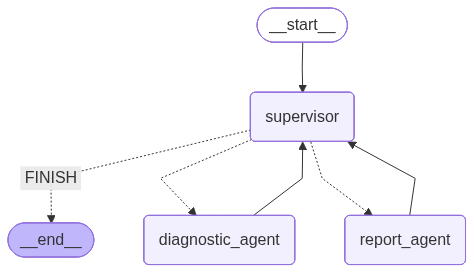

In [ ]:

# =========================================================
# 1) Etat partagé du graphe
# =========================================================
class MedicalState(TypedDict, total=False):
    messages: Annotated[list, add_messages]
    next: Literal["diagnostic_agent", "report_agent", "FINISH"]
    diagnostic_summary: str
    final_report: str


# =========================================================
# 2) Modèle
# =========================================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)


# =========================================================
# 3) Supervisor
#    - 1er passage -> diagnostic_agent
#    - 2e passage -> report_agent
#    - 3e passage -> FINISH
# =========================================================
def supervisor_node(state: MedicalState):
    if "diagnostic_summary" not in state:
        return {
            "next": "diagnostic_agent",
            "messages": [
                AIMessage(
                    content="Le supervisor envoie le dossier à diagnostic_agent.",
                    name="supervisor"
                )
            ]
        }

    if "final_report" not in state:
        return {
            "next": "report_agent",
            "messages": [
                AIMessage(
                    content="Le supervisor transmet l'analyse à report_agent pour rédaction finale.",
                    name="supervisor"
                )
            ]
        }

    return {
        "next": "FINISH",
        "messages": [
            AIMessage(
                content="Le supervisor clôt le workflow.",
                name="supervisor"
            )
        ]
    }


# =========================================================
# 4) Agent A1 : diagnostic général / orientation clinique
# =========================================================
def diagnostic_agent_node(state: MedicalState):
    response = llm.invoke([
        SystemMessage(content=(
            "Tu es un agent d'orientation clinique générale.\n"
            "Tu analyses les symptômes décrits par l'utilisateur et tu produis une synthèse clinique préliminaire.\n"
            "Tu ne poses PAS de diagnostic définitif.\n"
            "Tu dois fournir :\n"
            "1. Résumé clinique\n"
            "2. Hypothèses possibles\n"
            "3. Signes d'alerte éventuels\n"
            "4. Niveau d'urgence estimé\n"
            "5. Recommandations générales de consultation\n"
            "Sois prudent, clair et structuré."
        )),
        *state["messages"]
    ])

    return {
        "diagnostic_summary": response.content,
        "messages": [
            AIMessage(
                content=response.content,
                name="diagnostic_agent"
            )
        ]
    }


# =========================================================
# 5) Agent A2 : rapporteur médical
#    Reçoit le résultat de A1 et le transforme en rapport final
# =========================================================
def report_agent_node(state: MedicalState):
    response = llm.invoke([
        SystemMessage(content=(
            "Tu es un agent rapporteur médical.\n"
            "Ta mission est de transformer l'analyse fournie par diagnostic_agent "
            "en un rapport final clair, professionnel et lisible.\n"
            "Le rapport doit contenir les sections suivantes :\n"
            "- Motif principal\n"
            "- Symptômes rapportés\n"
            "- Synthèse clinique préliminaire\n"
            "- Hypothèses générales\n"
            "- Signes d'alerte\n"
            "- Niveau d'urgence\n"
            "- Conseils généraux\n"
            "- Mention de prudence : ce rapport ne remplace pas un avis médical.\n"
            "Le ton doit être clair et structuré."
        )),
        HumanMessage(content=(
            "Voici la demande initiale du patient :\n\n"
            f"{state['messages'][0].content}\n\n"
            "Voici l'analyse produite par diagnostic_agent :\n\n"
            f"{state['diagnostic_summary']}"
        ))
    ])

    return {
        "final_report": response.content,
        "messages": [
            AIMessage(
                content=response.content,
                name="report_agent"
            )
        ]
    }


# =========================================================
# 6) Routage
# =========================================================
def route_supervisor(state: MedicalState):
    return state["next"]


# =========================================================
# 7) Construction du graphe
# =========================================================
builder = StateGraph(MedicalState)

builder.add_node("supervisor", supervisor_node)
builder.add_node("diagnostic_agent", diagnostic_agent_node)
builder.add_node("report_agent", report_agent_node)

builder.add_edge(START, "supervisor")

builder.add_conditional_edges(
    "supervisor",
    route_supervisor,
    {
        "diagnostic_agent": "diagnostic_agent",
        "report_agent": "report_agent",
        "FINISH": END,
    }
)

builder.add_edge("diagnostic_agent", "supervisor")
builder.add_edge("report_agent", "supervisor")

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
result = graph.invoke({
    "messages": [
        HumanMessage(
            content=(
                "Patient de 45 ans présentant depuis 2 jours une toux, "
                "une fièvre modérée à 38,2°C, fatigue, et légère douleur thoracique "
                "à l'inspiration. Pas d'antécédent cardiaque connu."
            )
        )
    ]
})

2026-04-23 09:01:25,993 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-04-23 09:01:37,434 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


In [19]:
print("=== Diagnostic / orientation clinique (A1) ===")
print(display(Markdown((result["diagnostic_summary"]))))
print()

print("=== Rapport final (A2) ===")
print(display(Markdown(result["final_report"])))

=== Diagnostic / orientation clinique (A1) ===


1. **Résumé clinique :**
   - Patient de 45 ans.
   - Symptômes présents depuis 2 jours : toux, fièvre modérée (38,2°C), fatigue, légère douleur thoracique à l'inspiration.
   - Pas d'antécédent cardiaque connu.

2. **Hypothèses possibles :**
   - Infection respiratoire virale (ex. : bronchite, grippe).
   - Pneumonie (bactérienne ou virale).
   - Pleurésie (inflammation de la plèvre).
   - Éventuellement, une pathologie allergique ou irritative (moins probable compte tenu de la fièvre).

3. **Signes d'alerte éventuels :**
   - Aggravation de la douleur thoracique.
   - Difficulté respiratoire ou essoufflement.
   - Fièvre persistante ou élevée (supérieure à 39°C).
   - Expectoration de sang ou de mucus purulent.
   - Altération de l'état général (confusion, fatigue extrême).

4. **Niveau d'urgence estimé :**
   - Modéré. Bien que les symptômes ne soient pas immédiatement alarmants, la douleur thoracique et la fièvre nécessitent une évaluation médicale pour exclure des conditions plus graves.

5. **Recommandations générales de consultation :**
   - Consulter un médecin généraliste ou un service d'urgence si les symptômes s'aggravent ou si des signes d'alerte apparaissent.
   - En cas de symptômes persistants au-delà de 3 jours sans amélioration, une consultation est recommandée pour évaluer la nécessité d'examens complémentaires (radiographie thoracique, analyses sanguines, etc.). 
   - Repos, hydratation et éventuellement des antipyrétiques pour gérer la fièvre et la douleur.

None

=== Rapport final (A2) ===


**Rapport médical**

**Motif principal :**  
Patient de 45 ans présentant des symptômes respiratoires et fébriles depuis 2 jours.

**Symptômes rapportés :**  
- Toux  
- Fièvre modérée à 38,2°C  
- Fatigue  
- Légère douleur thoracique à l'inspiration  

**Synthèse clinique préliminaire :**  
Le patient, âgé de 45 ans, présente des symptômes respiratoires et une fièvre modérée depuis 2 jours. Il ne rapporte pas d'antécédents cardiaques connus, ce qui pourrait influencer l'évaluation de sa douleur thoracique.

**Hypothèses générales :**  
Les symptômes peuvent être attribués à plusieurs causes possibles, notamment :  
- Infection respiratoire virale (ex. : bronchite, grippe)  
- Pneumonie (bactérienne ou virale)  
- Pleurésie (inflammation de la plèvre)  
- Pathologie allergique ou irritative (moins probable compte tenu de la fièvre)  

**Signes d'alerte :**  
Le patient doit être vigilant et consulter un professionnel de santé si l'un des signes suivants apparaît :  
- Aggravation de la douleur thoracique  
- Difficulté respiratoire ou essoufflement  
- Fièvre persistante ou élevée (supérieure à 39°C)  
- Expectoration de sang ou de mucus purulent  
- Altération de l'état général (confusion, fatigue extrême)  

**Niveau d'urgence :**  
Le niveau d'urgence est estimé comme modéré. Bien que les symptômes ne soient pas immédiatement alarmants, la présence de douleur thoracique et de fièvre nécessite une évaluation médicale pour exclure des conditions plus graves.

**Conseils généraux :**  
- Consulter un médecin généraliste ou un service d'urgence si les symptômes s'aggravent ou si des signes d'alerte apparaissent.  
- En cas de symptômes persistants au-delà de 3 jours sans amélioration, une consultation est recommandée pour évaluer la nécessité d'examens complémentaires (radiographie thoracique, analyses sanguines, etc.).  
- Repos, hydratation et éventuellement des antipyrétiques pour gérer la fièvre et la douleur.  

**Mention de prudence :**  
Ce rapport ne remplace pas un avis médical. Il est essentiel de consulter un professionnel de santé pour un diagnostic et un traitement appropriés.

None


### Exemple 3 MAS avec Humain In The Loop

In [20]:
from typing import Annotated
from typing_extensions import TypedDict, Literal

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import (
    HumanMessage,
    AIMessage,
    SystemMessage,
    ToolMessage,
)


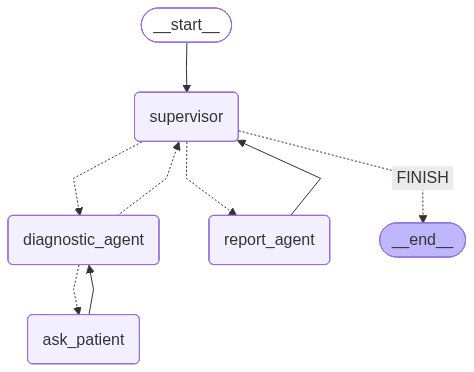

In [31]:

# =========================================================
# 1) Etat partagé
# =========================================================
class MedicalState(TypedDict, total=False):
    messages: Annotated[list, add_messages]
    next: Literal["diagnostic_agent", "report_agent", "FINISH"]
    question_count: int
    diagnostic_summary: str
    final_report: str


# =========================================================
# 2) LLMs
# =========================================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# Tool binding pour l'agent de diagnostic
# Le modèle saura qu'il peut appeler ask_patient(...)
# pour poser une question de clarification.
# =========================================================
@tool
def ask_patient(question: str) -> str:
    """Pose une question de clarification au patient et retourne sa réponse."""
    raise NotImplementedError("Ce tool est exécuté via interrupt() dans ask_patient_node.")


diagnostic_llm = llm.bind_tools([ask_patient])


# =========================================================
# 3) Supervisor
# =========================================================
def supervisor_node(state: MedicalState):
    if "diagnostic_summary" not in state:
        return {
            "next": "diagnostic_agent",
            "messages": [
                AIMessage(
                    content="Le supervisor envoie le dossier au diagnostic_agent.",
                    name="supervisor"
                )
            ]
        }

    if "final_report" not in state:
        return {
            "next": "report_agent",
            "messages": [
                AIMessage(
                    content="Le supervisor envoie la synthèse au report_agent.",
                    name="supervisor"
                )
            ]
        }

    return {
        "next": "FINISH",
        "messages": [
            AIMessage(
                content="Le supervisor clôt le workflow.",
                name="supervisor"
            )
        ]
    }


# =========================================================
# 4) Agent de diagnostic
#    - pose 5 questions via le tool ask_patient
#    - puis produit une synthèse clinique préliminaire
# =========================================================
def diagnostic_agent_node(state: MedicalState):
    count = state.get("question_count", 0)

    # Tant qu'on n'a pas encore posé 5 questions,
    # l'agent doit poser UNE question supplémentaire via l'outil.
    if count < 5:
        response = diagnostic_llm.invoke([
            SystemMessage(content=(
                "Tu es un agent d'orientation clinique générale.\n"
                "Tu ne poses jamais de diagnostic définitif.\n"
                "Tu dois poser exactement 5 questions de clarification, une par une, "
                "en utilisant l'outil ask_patient.\n"
                f"Questions déjà posées : {count}/5.\n"
                "Règles :\n"
                "- pose UNE seule question à la fois\n"
                "- choisis la question la plus utile cliniquement\n"
                "- sois bref et clair\n"
                "- utilise obligatoirement l'outil ask_patient tant que le compteur est < 5\n"
            )),
            *state["messages"]
        ])

        return {"messages": [response]}

    # Après 5 réponses, l'agent rédige sa synthèse
    response = llm.invoke([
        SystemMessage(content=(
            "Tu es un agent d'orientation clinique générale.\n"
            "Tu as déjà obtenu 5 réponses du patient.\n"
            "Rédige maintenant une synthèse clinique préliminaire structurée avec :\n"
            "1. Résumé du cas\n"
            "2. Hypothèses possibles\n"
            "3. Signes d'alerte\n"
            "4. Niveau d'urgence estimé\n"
            "5. Recommandations générales\n"
            "Important :\n"
            "- ne donne jamais de diagnostic définitif\n"
            "- rappelle que cela ne remplace pas un avis médical\n"
            "- reste prudent"
        )),
        *state["messages"]
    ])

    return {
        "diagnostic_summary": response.content,
        "messages": [
            AIMessage(content=response.content, name="diagnostic_agent")
        ]
    }


# =========================================================
# 5) Noeud d'exécution du tool ask_patient
#    Ici on interrompt le graphe pour demander une réponse
#    à l'utilisateur / patient / interface.
# =========================================================
def ask_patient_node(state: MedicalState):
    last_ai_message = state["messages"][-1]

    if not getattr(last_ai_message, "tool_calls", None):
        raise ValueError("Aucun tool_call trouvé dans le dernier message de l'agent.")

    tool_call = last_ai_message.tool_calls[0]
    question = tool_call["args"]["question"]

    # On interrompt le graphe pour demander la réponse humaine
    answer = interrupt({
        "type": "ask_patient",
        "question_number": state.get("question_count", 0) + 1,
        "question": question,
    })

    return {
        "question_count": state.get("question_count", 0) + 1,
        "messages": [
            ToolMessage(
                content=answer,
                tool_call_id=tool_call["id"]
            )
        ]
    }


# =========================================================
# 6) Agent rapporteur
#    Transforme la synthèse de diagnostic en rapport final
# =========================================================
def report_agent_node(state: MedicalState):
    response = llm.invoke([
        SystemMessage(content=(
            "Tu es un rapporteur médical.\n"
            "Ta mission est de transformer la synthèse clinique en rapport final clair et structuré.\n"
            "Le rapport doit contenir :\n"
            "- Motif principal\n"
            "- Informations recueillies\n"
            "- Synthèse clinique préliminaire\n"
            "- Hypothèses générales\n"
            "- Signes d'alerte\n"
            "- Niveau d'urgence\n"
            "- Conseils généraux\n"
            "- Mention explicite que cela ne remplace pas une consultation médicale\n"
            "Sois professionnel, prudent et lisible."
        )),
        HumanMessage(content=(
            "Voici la synthèse clinique préliminaire à transformer en rapport final :\n\n"
            f"{state['diagnostic_summary']}"
        ))
    ])

    return {
        "final_report": response.content,
        "messages": [
            AIMessage(content=response.content, name="report_agent")
        ]
    }


# =========================================================
# 7) Fonctions de routage
# =========================================================
def route_after_supervisor(state: MedicalState):
    return state["next"]


def route_after_diagnostic(state: MedicalState):
    # Si la synthèse est prête, on retourne au supervisor
    if "diagnostic_summary" in state:
        return "supervisor"

    # Sinon, on exécute le tool ask_patient
    return "ask_patient"


# =========================================================
# 8) Construction du graphe
# =========================================================
builder = StateGraph(MedicalState)

builder.add_node("supervisor", supervisor_node)
builder.add_node("diagnostic_agent", diagnostic_agent_node)
builder.add_node("ask_patient", ask_patient_node)
builder.add_node("report_agent", report_agent_node)

builder.add_edge(START, "supervisor")

builder.add_conditional_edges(
    "supervisor",
    route_after_supervisor,
    {
        "diagnostic_agent": "diagnostic_agent",
        "report_agent": "report_agent",
        "FINISH": END,
    }
)

builder.add_conditional_edges(
    "diagnostic_agent",
    route_after_diagnostic,
    {
        "ask_patient": "ask_patient",
        "supervisor": "supervisor",
    }
)

builder.add_edge("ask_patient", "diagnostic_agent")
builder.add_edge("report_agent", "supervisor")

memory = MemorySaver()
graph = builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:
config = {"configurable": {"thread_id": "patient-001"}}

result = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content=(
                    "J'ai de la fièvre, une toux sèche et mal à la gorge depuis 2 jours."
                )
            )
        ],
        "question_count": 0
    },
    config=config
)

2026-04-23 09:50:47,750 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


In [33]:
while "__interrupt__" in result:
    payload = result["__interrupt__"][0].value

    print(f"\nQuestion {payload['question_number']}/5")
    print(payload["question"])

    patient_answer = input("Réponse du patient : ")
    print("Patient Answer:", patient_answer)

    result = graph.invoke(
        Command(resume=patient_answer),
        config=config
    )


Question 1/5
Avez-vous d'autres symptômes, comme des douleurs musculaires, des maux de tête ou des difficultés respiratoires ?
Patient Answer: Fièvre


2026-04-23 09:51:05,627 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



Question 2/5
Avez-vous eu des contacts récents avec des personnes malades ou avez-vous voyagé récemment ?
Patient Answer: non


2026-04-23 09:51:13,528 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



Question 3/5
Prenez-vous des médicaments ou avez-vous des antécédents médicaux particuliers ?
Patient Answer: non


2026-04-23 09:51:22,847 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



Question 4/5
Avez-vous remarqué des changements dans votre appétit ou votre niveau d'énergie ?
Patient Answer: oui


2026-04-23 09:51:28,707 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



Question 5/5
Pouvez-vous décrire les changements dans votre appétit ou votre niveau d'énergie ?
Patient Answer: Je me sens très faible


2026-04-23 09:51:55,176 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-04-23 09:52:03,355 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


In [34]:
print("\n=== RAPPORT FINAL ===\n")
print(display(Markdown(result["final_report"])))


=== RAPPORT FINAL ===



# Rapport Final

## Motif principal
Le patient présente des symptômes de fièvre, de toux sèche et de mal de gorge, accompagnés d'une sensation de grande faiblesse, sur une durée de 2 jours.

## Informations recueillies
- **Symptômes :** Fièvre, toux sèche, mal de gorge, grande faiblesse.
- **Antécédents médicaux :** Aucun antécédent médical particulier ni prise de médicaments rapportés.
- **Contacts récents :** Pas de contacts avec des personnes malades ni de voyages récents.

## Synthèse clinique préliminaire
Le tableau clinique du patient suggère une infection potentiellement virale ou bactérienne. Les symptômes actuels, bien que non immédiatement menaçants, nécessitent une surveillance attentive en raison de la faiblesse et de la fièvre présentes.

## Hypothèses générales
1. Infection virale (ex. : grippe, COVID-19, rhinopharyngite).
2. Infection bactérienne (ex. : angine streptococcique).
3. Autres causes infectieuses ou inflammatoires.

## Signes d'alerte
Le patient doit être vigilant et surveiller l'apparition des signes suivants :
- Aggravation de la toux, surtout si elle devient productive.
- Difficultés respiratoires.
- Fièvre persistante ou élevée.
- Déshydratation (diminution de l'appétit et de l'énergie).
- Apparition de nouveaux symptômes (ex. : éruption cutanée, douleurs thoraciques).

## Niveau d'urgence
- **Modéré :** Bien que les symptômes ne semblent pas immédiatement menaçants, la faiblesse et la fièvre nécessitent une attention médicale pour évaluer l'évolution de l'état de santé.

## Conseils généraux
- Surveillez l'évolution des symptômes et notez tout changement significatif.
- Restez bien hydraté et reposez-vous.
- Si les symptômes s'aggravent ou si des signes d'alerte apparaissent, consultez un professionnel de santé rapidement.

**Important :** Ce rapport ne remplace pas une consultation médicale. Il est essentiel de consulter un médecin pour un examen clinique et des tests appropriés.

Restez prudent et prenez soin de vous.

None


## Exemple 4 : Medical MAS

In [35]:
from typing import Annotated
from typing_extensions import TypedDict, Literal

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import (
    HumanMessage,
    AIMessage,
    SystemMessage,
    ToolMessage,
)


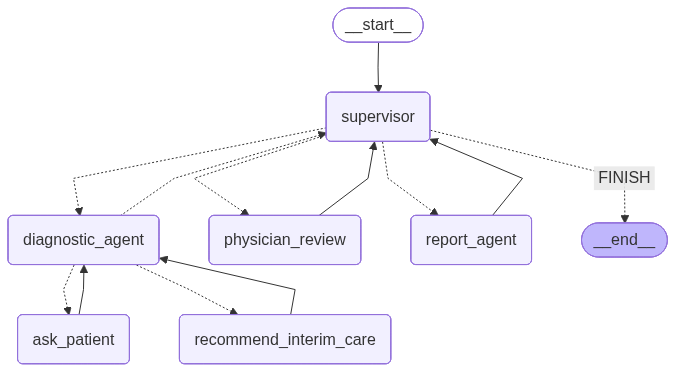

In [49]:
# =========================================================
# 1) Etat partagé
# =========================================================
class MedicalState(TypedDict, total=False):
    messages: Annotated[list, add_messages]

    next: Literal[
        "diagnostic_agent",
        "physician_review",
        "report_agent",
        "FINISH",
    ]

    question_count: int
    interim_care: str
    diagnostic_summary: str
    physician_treatment: str
    final_report: str


# =========================================================
# 2) LLM
# =========================================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)


# =========================================================
# 3) Tools
# =========================================================
@tool
def ask_patient(question: str) -> str:
    """Pose une question de clarification au patient et retourne sa réponse."""
    raise NotImplementedError("Ce tool est géré dans un noeud LangGraph via interrupt().")


@tool
def recommend_interim_care(clinical_context: str, urgency_level: str) -> str:
    """
    Retourne une recommandation intermédiaire générale de prise en charge.
    Ne remplace pas un avis médical ni une prescription.
    """
    urgency = urgency_level.lower().strip()

    if urgency in ["urgent", "élevé", "eleve"]:
        return (
            "Prise en charge intermédiaire suggérée :\n"
            "- évaluation médicale urgente recommandée ;\n"
            "- repos strict ;\n"
            "- éviter les efforts ;\n"
            "- hydratation si possible ;\n"
            "- surveillance rapprochée ;\n"
            "- consulter en urgence en cas d'aggravation, confusion, détresse respiratoire "
            "ou douleur thoracique importante."
        )

    if urgency in ["modéré", "modere"]:
        return (
            "Prise en charge intermédiaire suggérée :\n"
            "- repos ;\n"
            "- bonne hydratation ;\n"
            "- surveillance de l'évolution ;\n"
            "- éviter les efforts importants ;\n"
            "- avis médical dans un délai rapproché ;\n"
            "- consulter plus rapidement en cas d'aggravation ou de signes d'alerte."
        )

    return (
        "Prise en charge intermédiaire suggérée :\n"
        "- repos ;\n"
        "- hydratation ;\n"
        "- surveillance des symptômes ;\n"
        "- mesures simples de confort ;\n"
        "- consultation si persistance ou aggravation."
    )


diagnostic_llm = llm.bind_tools([ask_patient, recommend_interim_care])


# =========================================================
# 4) Supervisor
# =========================================================
def supervisor_node(state: MedicalState):
    if "diagnostic_summary" not in state:
        return {
            "next": "diagnostic_agent",
            "messages": [
                AIMessage(
                    content="Le supervisor envoie le dossier au diagnostic_agent.",
                    name="supervisor"
                )
            ]
        }

    if "physician_treatment" not in state:
        return {
            "next": "physician_review",
            "messages": [
                AIMessage(
                    content="Le supervisor demande une revue humaine par le médecin traitant.",
                    name="supervisor"
                )
            ]
        }

    if "final_report" not in state:
        return {
            "next": "report_agent",
            "messages": [
                AIMessage(
                    content="Le supervisor envoie le dossier complet au report_agent.",
                    name="supervisor"
                )
            ]
        }

    return {
        "next": "FINISH",
        "messages": [
            AIMessage(
                content="Le supervisor clôt le workflow.",
                name="supervisor"
            )
        ]
    }


# =========================================================
# 5) Agent de diagnostic
#    - pose 5 questions
#    - appelle recommend_interim_care
#    - rédige la synthèse clinique
# =========================================================
def diagnostic_agent_node(state: MedicalState):
    count = state.get("question_count", 0)

    # Etape 1 : 5 questions au patient
    if count < 5:
        response = diagnostic_llm.invoke([
            SystemMessage(content=(
                "Tu es un agent d'orientation clinique générale.\n"
                "Tu ne donnes jamais de diagnostic définitif.\n"
                "Tu dois poser exactement 5 questions de clarification, une par une, "
                "en utilisant le tool ask_patient.\n"
                f"Questions déjà posées : {count}/5.\n"
                "Règles :\n"
                "- pose UNE seule question à la fois\n"
                "- choisis la question la plus utile cliniquement\n"
                "- sois bref et clair\n"
                "- utilise obligatoirement ask_patient tant que le compteur est < 5"
            )),
            *state["messages"]
        ])
        return {"messages": [response]}

    # Etape 2 : recommandation intermédiaire
    if "interim_care" not in state:
        response = diagnostic_llm.invoke([
            SystemMessage(content=(
                "Tu es un agent d'orientation clinique générale.\n"
                "Tu as obtenu 5 réponses du patient.\n"
                "Tu dois maintenant appeler le tool recommend_interim_care.\n"
                "Déduis un niveau d'urgence parmi : faible, modéré, élevé, urgent.\n"
                "Fournis aussi un clinical_context court.\n"
                "N'écris pas encore la synthèse finale."
            )),
            *state["messages"]
        ])
        return {"messages": [response]}

    # Etape 3 : synthèse clinique
    response = llm.invoke([
        SystemMessage(content=(
            "Tu es un agent d'orientation clinique générale.\n"
            "Rédige une synthèse clinique préliminaire structurée contenant :\n"
            "1. Résumé du cas\n"
            "2. Hypothèses possibles\n"
            "3. Signes d'alerte\n"
            "4. Niveau d'urgence estimé\n"
            "5. Recommandation intermédiaire\n"
            "6. Recommandations générales\n"
            "Important :\n"
            "- ne donne jamais de diagnostic définitif\n"
            "- indique que cela ne remplace pas un avis médical\n"
            "- ton prudent et structuré"
        )),
        *state["messages"],
        HumanMessage(content=(
            "Voici la recommandation intermédiaire à intégrer :\n\n"
            f"{state['interim_care']}"
        ))
    ])

    return {
        "diagnostic_summary": response.content,
        "messages": [
            AIMessage(content=response.content, name="diagnostic_agent")
        ]
    }


# =========================================================
# 6) Noeud ask_patient : Human-in-the-loop côté patient
# =========================================================
def ask_patient_node(state: MedicalState):
    last_ai_message = state["messages"][-1]

    if not getattr(last_ai_message, "tool_calls", None):
        raise ValueError("Aucun tool_call trouvé pour ask_patient.")

    tool_call = last_ai_message.tool_calls[0]
    question = tool_call["args"]["question"]

    answer = interrupt({
        "type": "ask_patient",
        "question_number": state.get("question_count", 0) + 1,
        "question": question,
    })

    return {
        "question_count": state.get("question_count", 0) + 1,
        "messages": [
            ToolMessage(
                content=answer,
                tool_call_id=tool_call["id"]
            )
        ]
    }


# =========================================================
# 7) Noeud tool recommend_interim_care
# =========================================================
def interim_care_tool_node(state: MedicalState):
    last_ai_message = state["messages"][-1]

    if not getattr(last_ai_message, "tool_calls", None):
        raise ValueError("Aucun tool_call trouvé pour recommend_interim_care.")

    tool_call = last_ai_message.tool_calls[0]
    args = tool_call["args"]

    recommendation = recommend_interim_care.invoke(args)

    return {
        "interim_care": recommendation,
        "messages": [
            ToolMessage(
                content=recommendation,
                tool_call_id=tool_call["id"]
            )
        ]
    }


# =========================================================
# 8) Human-in-the-loop médecin traitant
#    Le médecin lit la synthèse et propose le traitement.
# =========================================================
def physician_review_node(state: MedicalState):
    physician_input = interrupt({
        "type": "physician_review",
        "instruction": (
            "Le médecin traitant doit examiner la synthèse clinique et proposer "
            "un traitement / plan thérapeutique / conduite à tenir."
        ),
        "diagnostic_summary": state["diagnostic_summary"],
        "interim_care": state.get("interim_care", ""),
    })

    return {
        "physician_treatment": physician_input,
        "messages": [
            HumanMessage(
                content=f"Traitement / conduite à tenir proposé(e) par le médecin traitant :\n{physician_input}",
                name="treating_physician"
            )
        ]
    }


# =========================================================
# 9) Agent rapporteur
# =========================================================
def report_agent_node(state: MedicalState):
    response = llm.invoke([
        SystemMessage(content=(
            "Tu es un rapporteur médical.\n"
            "Rédige un rapport final clair, structuré et professionnel.\n"
            "Le rapport doit contenir :\n"
            "- Motif principal\n"
            "- Informations recueillies\n"
            "- Synthèse clinique préliminaire\n"
            "- Hypothèses générales\n"
            "- Signes d'alerte\n"
            "- Niveau d'urgence\n"
            "- Recommandation intermédiaire\n"
            "- Traitement / conduite à tenir proposé(e) par le médecin traitant\n"
            "- Mention explicite que l'orientation initiale IA ne remplace pas un avis médical\n"
            "Le traitement final doit être présenté comme venant du médecin traitant."
        )),
        HumanMessage(content=(
            "Voici les éléments à intégrer dans le rapport final.\n\n"
            f"Synthèse clinique préliminaire :\n{state['diagnostic_summary']}\n\n"
            f"Recommandation intermédiaire :\n{state.get('interim_care', '')}\n\n"
            f"Traitement / conduite à tenir du médecin traitant :\n{state['physician_treatment']}"
        ))
    ])

    return {
        "final_report": response.content,
        "messages": [
            AIMessage(content=response.content, name="report_agent")
        ]
    }


# =========================================================
# 10) Routage
# =========================================================
def route_after_supervisor(state: MedicalState):
    return state["next"]


def route_after_diagnostic(state: MedicalState):
    if "diagnostic_summary" in state:
        return "supervisor"

    last_message = state["messages"][-1]

    if getattr(last_message, "tool_calls", None):
        tool_name = last_message.tool_calls[0]["name"]

        if tool_name == "ask_patient":
            return "ask_patient"

        if tool_name == "recommend_interim_care":
            return "recommend_interim_care"

    raise ValueError("Le diagnostic_agent devait soit appeler un tool, soit produire diagnostic_summary.")


# =========================================================
# 11) Construction du graphe
# =========================================================
builder = StateGraph(MedicalState)

builder.add_node("supervisor", supervisor_node)
builder.add_node("diagnostic_agent", diagnostic_agent_node)
builder.add_node("ask_patient", ask_patient_node)
builder.add_node("recommend_interim_care", interim_care_tool_node)
builder.add_node("physician_review", physician_review_node)
builder.add_node("report_agent", report_agent_node)

builder.add_edge(START, "supervisor")

builder.add_conditional_edges(
    "supervisor",
    route_after_supervisor,
    {
        "diagnostic_agent": "diagnostic_agent",
        "physician_review": "physician_review",
        "report_agent": "report_agent",
        "FINISH": END,
    }
)

builder.add_conditional_edges(
    "diagnostic_agent",
    route_after_diagnostic,
    {
        "ask_patient": "ask_patient",
        "recommend_interim_care": "recommend_interim_care",
        "supervisor": "supervisor",
    }
)

builder.add_edge("ask_patient", "diagnostic_agent")
builder.add_edge("recommend_interim_care", "diagnostic_agent")
builder.add_edge("physician_review", "supervisor")
builder.add_edge("report_agent", "supervisor")

memory = MemorySaver()
graph = builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

### 1) Démarrer le graphe

In [50]:
config = {"configurable": {"thread_id": "patient-001"}}

result = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="J'ai de la fièvre, une toux sèche et une fatigue importante depuis 3 jours."
            )
        ],
        "question_count": 0
    },
    config=config
)

2026-04-23 10:43:11,383 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


### 2) Gérer les interruptions patient + médecin

Ici, on peut avoir deux types d’interruptions :

- ask_patient
- physician_review

In [51]:
while "__interrupt__" in result:
    payload = result["__interrupt__"][0].value

    if payload["type"] == "ask_patient":
        print(f"\n[Patient] Question {payload['question_number']}/5")
        print(payload["question"])
        user_input = input("Réponse du patient : ")
        print(user_input)

    elif payload["type"] == "physician_review":
        print("\n[Médecin traitant] Revue clinique requise")
        print("\n--- Synthèse clinique ---")
        print(payload["diagnostic_summary"])
        print("\n--- Recommandation intermédiaire ---")
        print(payload["interim_care"])
        print("\nVeuillez saisir le traitement / la conduite à tenir du médecin.")
        user_input = input("Traitement du médecin : ")
        print(user_input)

    else:
        raise ValueError(f"Type d'interruption inconnu: {payload['type']}")

    result = graph.invoke(
        Command(resume=user_input),
        config=config
    )


[Patient] Question 1/5
Avez-vous d'autres symptômes, comme des douleurs corporelles, des maux de tête ou des difficultés respiratoires ?
Vomissements


2026-04-23 10:43:24,084 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



[Patient] Question 2/5
Avez-vous eu des contacts récents avec des personnes malades ou avez-vous voyagé récemment ?
non


2026-04-23 10:43:33,221 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



[Patient] Question 3/5
Prenez-vous des médicaments ou avez-vous des antécédents médicaux particuliers ?
non


2026-04-23 10:43:36,865 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


... (2 outputs left out)


[Patient] Question 5/5
Avez-vous des allergies connues ou des problèmes respiratoires chroniques ?
non


2026-04-23 10:43:49,612 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
2026-04-23 10:43:57,641 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"



[Médecin traitant] Revue clinique requise

--- Synthèse clinique ---
### Synthèse Clinique Préliminaire

1. **Résumé du cas :**
   Le patient présente des symptômes de fièvre, une toux sèche, une fatigue importante et des vomissements depuis 3 jours. Aucun antécédent médical significatif ou contact récent avec des personnes malades n'est rapporté.

2. **Hypothèses possibles :**
   - Infection virale (ex. : grippe, COVID-19)
   - Infection bactérienne (ex. : pneumonie)
   - Réaction à un agent irritant ou allergène
   - Autres causes infectieuses ou non infectieuses

3. **Signes d'alerte :**
   - Difficultés respiratoires
   - Aggravation de la fièvre
   - Déshydratation (signes tels que sécheresse de la bouche, urines foncées)
   - Confusion ou altération de l'état de conscience

4. **Niveau d'urgence estimé :**
   Modéré. Bien que les symptômes ne semblent pas immédiatement menaçants, une surveillance est nécessaire.

5. **Recommandation intermédiaire :**
   - Repos
   - Bonne hydrat

2026-04-23 10:44:25,843 - httpx - INFO - HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"


In [52]:
print("\n=== TRAITEMENT DU MEDECIN ===\n")
print(result["physician_treatment"])

print("\n=== RAPPORT FINAL ===\n")
print(display(Markdown(result["final_report"])))


=== TRAITEMENT DU MEDECIN ===

T1, T2, T3

=== RAPPORT FINAL ===



# Rapport Final

## Motif Principal
Le patient se présente avec des symptômes de fièvre, toux sèche, fatigue importante et vomissements, persistants depuis 3 jours.

## Informations Recueillies
Le patient ne rapporte aucun antécédent médical significatif ni contact récent avec des personnes malades. Les symptômes sont apparus de manière aiguë et se sont intensifiés au cours des derniers jours.

## Synthèse Clinique Préliminaire
1. **Résumé du cas :**
   Le patient présente des symptômes de fièvre, une toux sèche, une fatigue importante et des vomissements depuis 3 jours. Aucun antécédent médical significatif ou contact récent avec des personnes malades n'est rapporté.

2. **Hypothèses possibles :**
   - Infection virale (ex. : grippe, COVID-19)
   - Infection bactérienne (ex. : pneumonie)
   - Réaction à un agent irritant ou allergène
   - Autres causes infectieuses ou non infectieuses

3. **Signes d'alerte :**
   - Difficultés respiratoires
   - Aggravation de la fièvre
   - Déshydratation (signes tels que sécheresse de la bouche, urines foncées)
   - Confusion ou altération de l'état de conscience

4. **Niveau d'urgence estimé :**
   Modéré. Bien que les symptômes ne semblent pas immédiatement menaçants, une surveillance est nécessaire.

## Recommandation Intermédiaire
- Repos
- Bonne hydratation
- Surveillance de l'évolution des symptômes
- Éviter les efforts importants
- Avis médical dans un délai rapproché
- Consulter plus rapidement en cas d'aggravation ou de signes d'alerte

## Traitement / Conduite à Tenir Proposé(e) par le Médecin Traitant
Le médecin traitant a recommandé les mesures suivantes :
- T1 : Antipyrétiques pour la gestion de la fièvre
- T2 : Hydratation orale avec des solutions de réhydratation
- T3 : Surveillance des symptômes et consultation si aggravation

**Important :** Cette synthèse ne remplace pas un avis médical. Il est recommandé de consulter un professionnel de santé pour un examen approfondi et un diagnostic approprié.

None
